# Análisis de requerimientos de equipos de poder a partir de QRS
**Sector:** dispositivos médicos (ortopedia y trauma) · **Periodo:** enero–octubre 2026 · **Autora:** Starleen Gaviria Medina

### Contexto
Una empresa fabricante de dispositivos médicos presta, en cada cirugía de trauma, **equipos de poder** (motores, perforadores y sierras). Parte del inventario es **neumático** (manguera y bala de nitrógeno) y los cirujanos piden cada vez más **motores eléctricos de batería**. Esas solicitudes llegaban como texto libre en el sistema de Quejas, Reclamos y Sugerencias (QRS).

### Pregunta de negocio
¿Cuál es la demanda de motores eléctricos, en qué tipo de equipo (**Pequeños** o **Grandes Fragmentos**) y dónde se concentra?

### Sobre los datos
Este notebook usa un **dataset anonimizado** de 55 requerimientos: ciudades, instituciones, pagadores y remisiones están codificados (`Ciudad_A`, `Inst_01`, `Pagador_01`, `REM_001`), los nombres comerciales de los sistemas se reemplazaron por descripciones genéricas y no se incluyen las descripciones originales. El proceso previo (extracción por API, limpieza, clasificación del texto y cruce con el sistema de despachos) se describe en el `README.md`.

## 1. Librerías y estilo corporativo

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

VERDE_OSCURO = "#38761D"
VERDE_CLARO  = "#92D050"
VERDE_MEDIO  = "#6AA84F"
NEGRO        = "#1A1A1A"
GRIS_VERDOSO = "#E1DED0"

sns.set_theme(style="white")
plt.rcParams.update({
    "axes.edgecolor": "#9E9E9E", "axes.titleweight": "bold", "axes.titlesize": 14,
    "axes.labelcolor": NEGRO, "text.color": NEGRO, "xtick.color": NEGRO, "ytick.color": NEGRO,
})
CARPETA_GRAFICOS = "../graficos" if os.path.isdir("../graficos") else "graficos"
os.makedirs(CARPETA_GRAFICOS, exist_ok=True)

## 2. Carga de datos
Funciona en local (desde la carpeta `notebook/`), en Google Colab desde GitHub o subiendo el archivo manualmente.

In [2]:
RUTA_LOCAL = "../data/dataset_anonimizado.csv"
URL_GITHUB = "https://raw.githubusercontent.com/TU-USUARIO/TU-REPOSITORIO/main/data/dataset_anonimizado.csv"

if os.path.exists(RUTA_LOCAL):
    df = pd.read_csv(RUTA_LOCAL)
else:
    try:
        df = pd.read_csv(URL_GITHUB)
    except Exception:
        from google.colab import files          # alternativa: subir el CSV
        subido = files.upload()
        df = pd.read_csv(list(subido.keys())[0])

T  = "TIPO_EQUIPO_PODER"
GF, PF = "Grandes Fragmentos", "Pequeños Fragmentos"
N  = len(df)
df.head()

,ID,ANIO,MES,CIUDAD,INSTITUCION,PAGADOR,SISTEMA,REMISION,TIPO_EQUIPO_PODER,ADVERTENCIA
0,1,2026,2026-02,Ciudad_A,Inst_03,Pagador_02,Clavo reconstrucción femoral (línea A),REM_001,Grandes Fragmentos,No
1,2,2026,2026-02,Ciudad_A,Inst_14,Pagador_01,Clavo cefalomedular fémur proximal,REM_002,Grandes Fragmentos,No
2,3,2026,2026-03,Ciudad_C,Inst_11,Pagador_09,Clavo supracondíleo,REM_003,Grandes Fragmentos,No
3,4,2026,2026-03,Ciudad_E,Inst_08,Pagador_06,Placa bloqueada radio distal,REM_004,Pequeños Fragmentos,Sí
4,5,2026,2026-03,Ciudad_E,Inst_08,Pagador_06,Placa bloqueada radio distal,REM_004,Pequeños Fragmentos,No


## 3. Perfil y calidad de los datos

In [3]:
print(f"Registros: {N} · Columnas: {df.shape[1]}")
perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1),
    "valores únicos": df.nunique(),
})
perfil

Registros: 55 · Columnas: 10


,tipo,nulos,% nulos,valores únicos
ID,int64,0,0.0,55
ANIO,int64,0,0.0,1
MES,str,0,0.0,9
CIUDAD,str,0,0.0,5
INSTITUCION,str,0,0.0,25
PAGADOR,str,0,0.0,18
SISTEMA,str,0,0.0,21
REMISION,str,3,5.5,50
TIPO_EQUIPO_PODER,str,0,0.0,2
ADVERTENCIA,str,0,0.0,2


In [4]:
# Remisiones repetidas: pueden ser reportes distintos de una misma cirugía (no son duplicados exactos)
rep = df["REMISION"].value_counts()
print(f"Remisiones con más de un reporte: {(rep > 1).sum()}")
print(f"Remisiones sin dato: {df['REMISION'].isna().sum()}")
print(f"Filas duplicadas exactas: {df.drop(columns='ID').duplicated().sum()}")

Remisiones con más de un reporte: 2
Remisiones sin dato: 3
Filas duplicadas exactas: 0


**Variable `ADVERTENCIA`:** se calculó sobre las descripciones originales (no publicadas) con una expresión regular que detecta advertencias de escalamiento. Este es el patrón usado:
```python
patron = r"cancel|otra casa|segunda opci[oó]n|no (?:volver[aá]? a|va a) (?:operar|aceptar)|no acepta|no opera|jam[aá]s|nunca m[aá]s|operar con nosotros"
df["ADVERTENCIA"] = np.where(df["DESCRIPCION"].str.contains(patron, case=False, na=False), "Sí", "No")
```

## 4. Funciones de apoyo

In [5]:
def acabado(fig, ax, nombre, titulo, subtitulo):
    """Título, subtítulo, fuente al pie y guardado en PNG."""
    ax.set_title(titulo, loc="left", pad=26, color=NEGRO)
    ax.text(0, 1.02, subtitulo, transform=ax.transAxes, fontsize=9.5, color="#555555")
    sns.despine(ax=ax)
    fig.text(0.01, 0.01, f"Fuente: sistema QRS + sistema de despachos (datos anonimizados) · Ene–Oct 2026 · n = {N}",
             fontsize=7.5, color="#777777")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(os.path.join(CARPETA_GRAFICOS, nombre), dpi=200)
    plt.show()

def corto(texto, n=34):
    t = str(texto)
    return t if len(t) <= n else t[:n-1] + "…"

LEYENDA = [GF, PF]
meses = [f"2026-{m:02d}" for m in range(1, 11)]
etiquetas = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct"]

## Pregunta 1. ¿Cuántos requerimientos corresponden a Pequeños y Grandes Fragmentos?
**Gráfico:** Barras horizontales con cantidad y porcentaje.

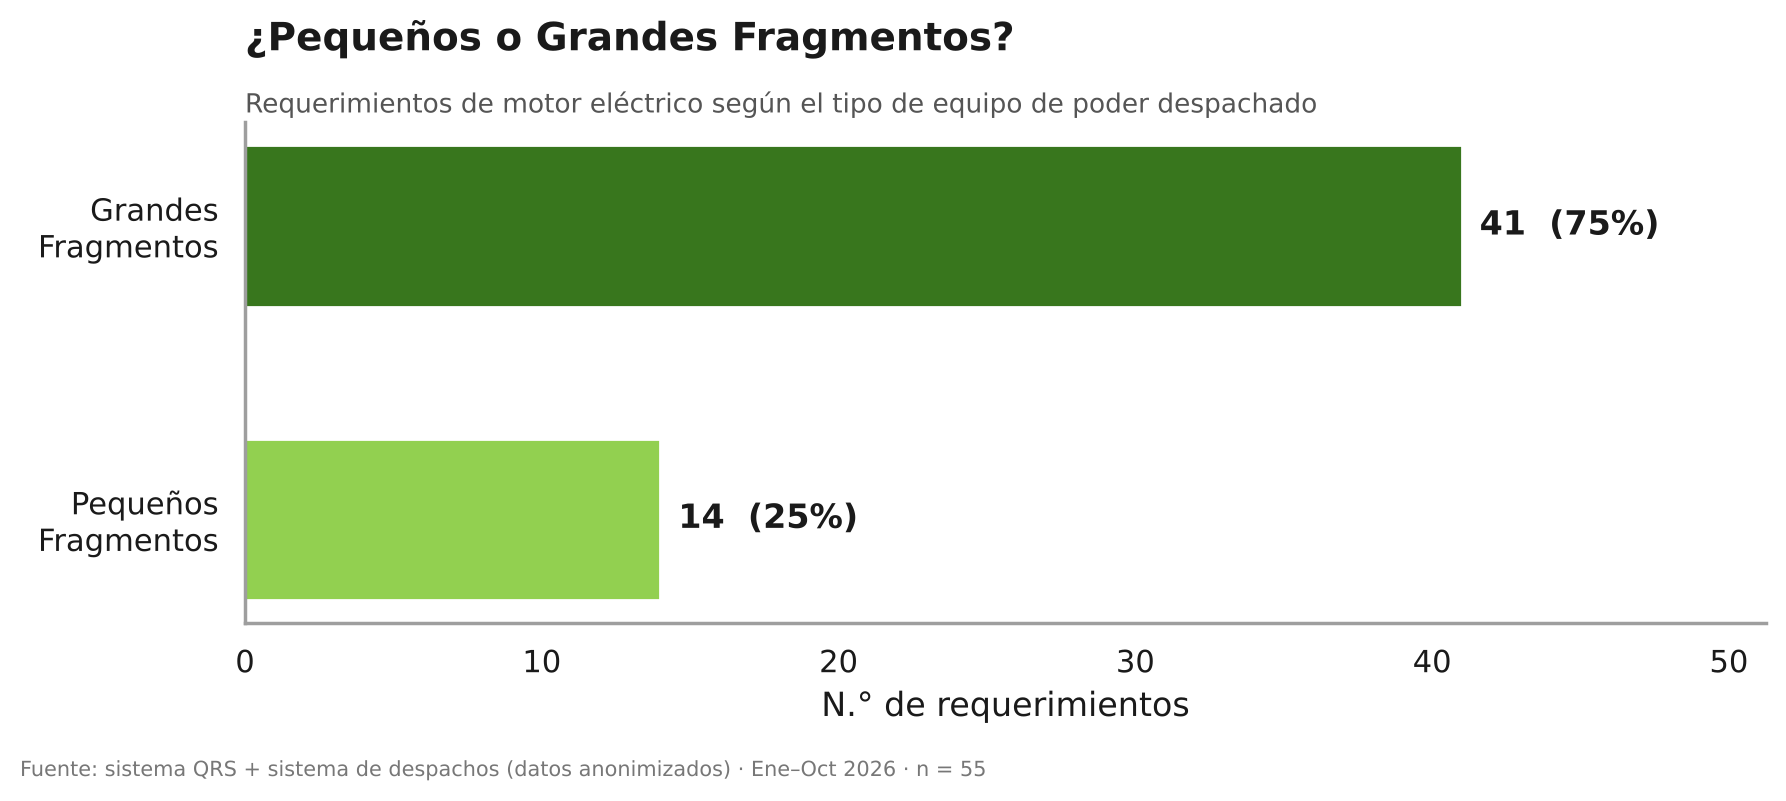

In [6]:
conteo = df[T].value_counts().reindex([GF, PF])

fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.barh(["Grandes\nFragmentos", "Pequeños\nFragmentos"], conteo.values,
                 color=[VERDE_OSCURO, VERDE_CLARO], height=0.55)
for b, v in zip(barras, conteo.values):
    ax.text(v + 0.6, b.get_y() + b.get_height()/2, f"{v}  ({v/N:.0%})", va="center", fontweight="bold", fontsize=12)
ax.invert_yaxis(); ax.set_xlim(0, conteo.max() * 1.25); ax.set_xlabel("N.° de requerimientos")
acabado(fig, ax, "01_pequenos_vs_grandes_fragmentos.png", "¿Pequeños o Grandes Fragmentos?",
        "Requerimientos de motor eléctrico según el tipo de equipo de poder despachado")

**Respuesta:** El **75 %** de los requerimientos (41) corresponde a **Grandes Fragmentos** y el 25 % (14) a Pequeños Fragmentos: cerca de 3 a 1.

## Pregunta 2. ¿Qué ciudades concentran los requerimientos?
**Gráfico:** Barras horizontales apiladas.

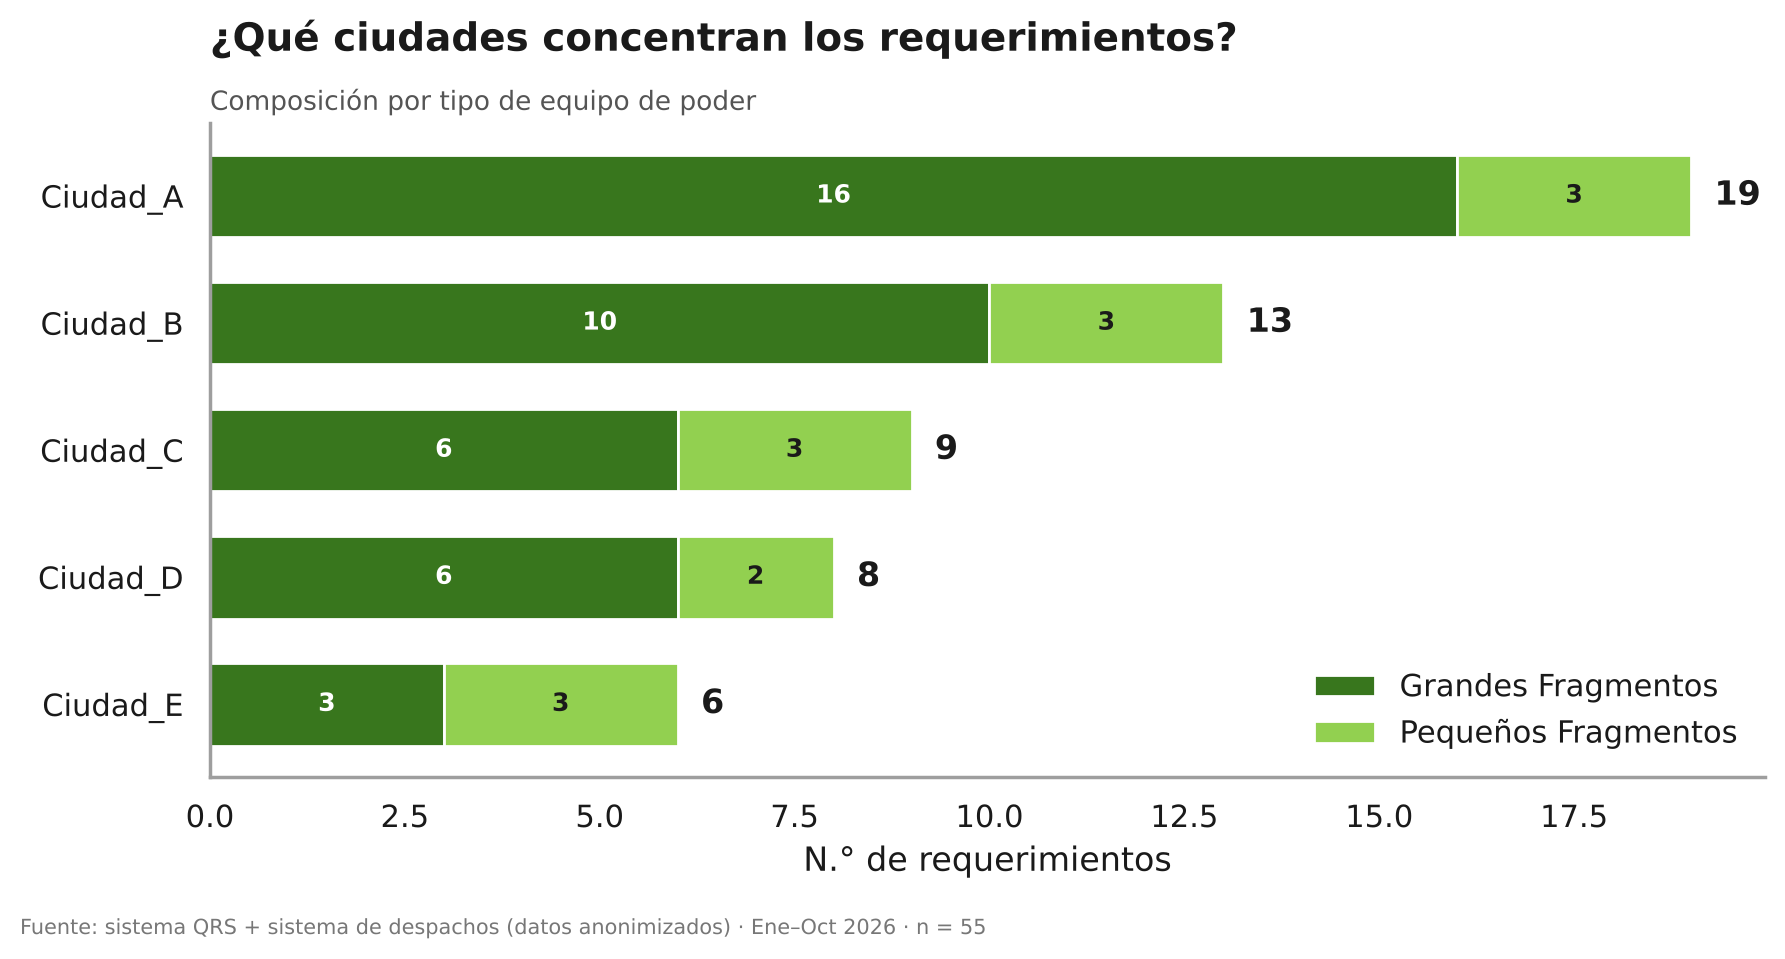

In [7]:
ct = pd.crosstab(df["CIUDAD"], df[T]).reindex(columns=[GF, PF], fill_value=0)
ct = ct.loc[ct.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 4.8))
ct.plot.barh(stacked=True, color=[VERDE_OSCURO, VERDE_CLARO], ax=ax, width=0.65)
for i, (_, fila) in enumerate(ct.iterrows()):
    x = 0
    for col in ct.columns:
        if fila[col] > 0:
            ax.text(x + fila[col]/2, i, str(fila[col]), ha="center", va="center",
                    color="white" if col == GF else NEGRO, fontsize=9, fontweight="bold")
        x += fila[col]
    ax.text(x + 0.3, i, str(x), va="center", fontweight="bold")
ax.set_ylabel(""); ax.set_xlabel("N.° de requerimientos"); ax.legend(LEYENDA, frameon=False, loc="lower right")
acabado(fig, ax, "02_ciudad_por_tipo.png", "¿Qué ciudades concentran los requerimientos?", "Composición por tipo de equipo de poder")

**Respuesta:** **Ciudad_A y Ciudad_B** (de una misma región) concentran el **58 %** de los requerimientos; en Ciudad_A, 16 de 19 son de Grandes Fragmentos.

## Pregunta 3. ¿Qué instituciones son las más recurrentes?
**Gráfico:** Top 10 en barras apiladas.

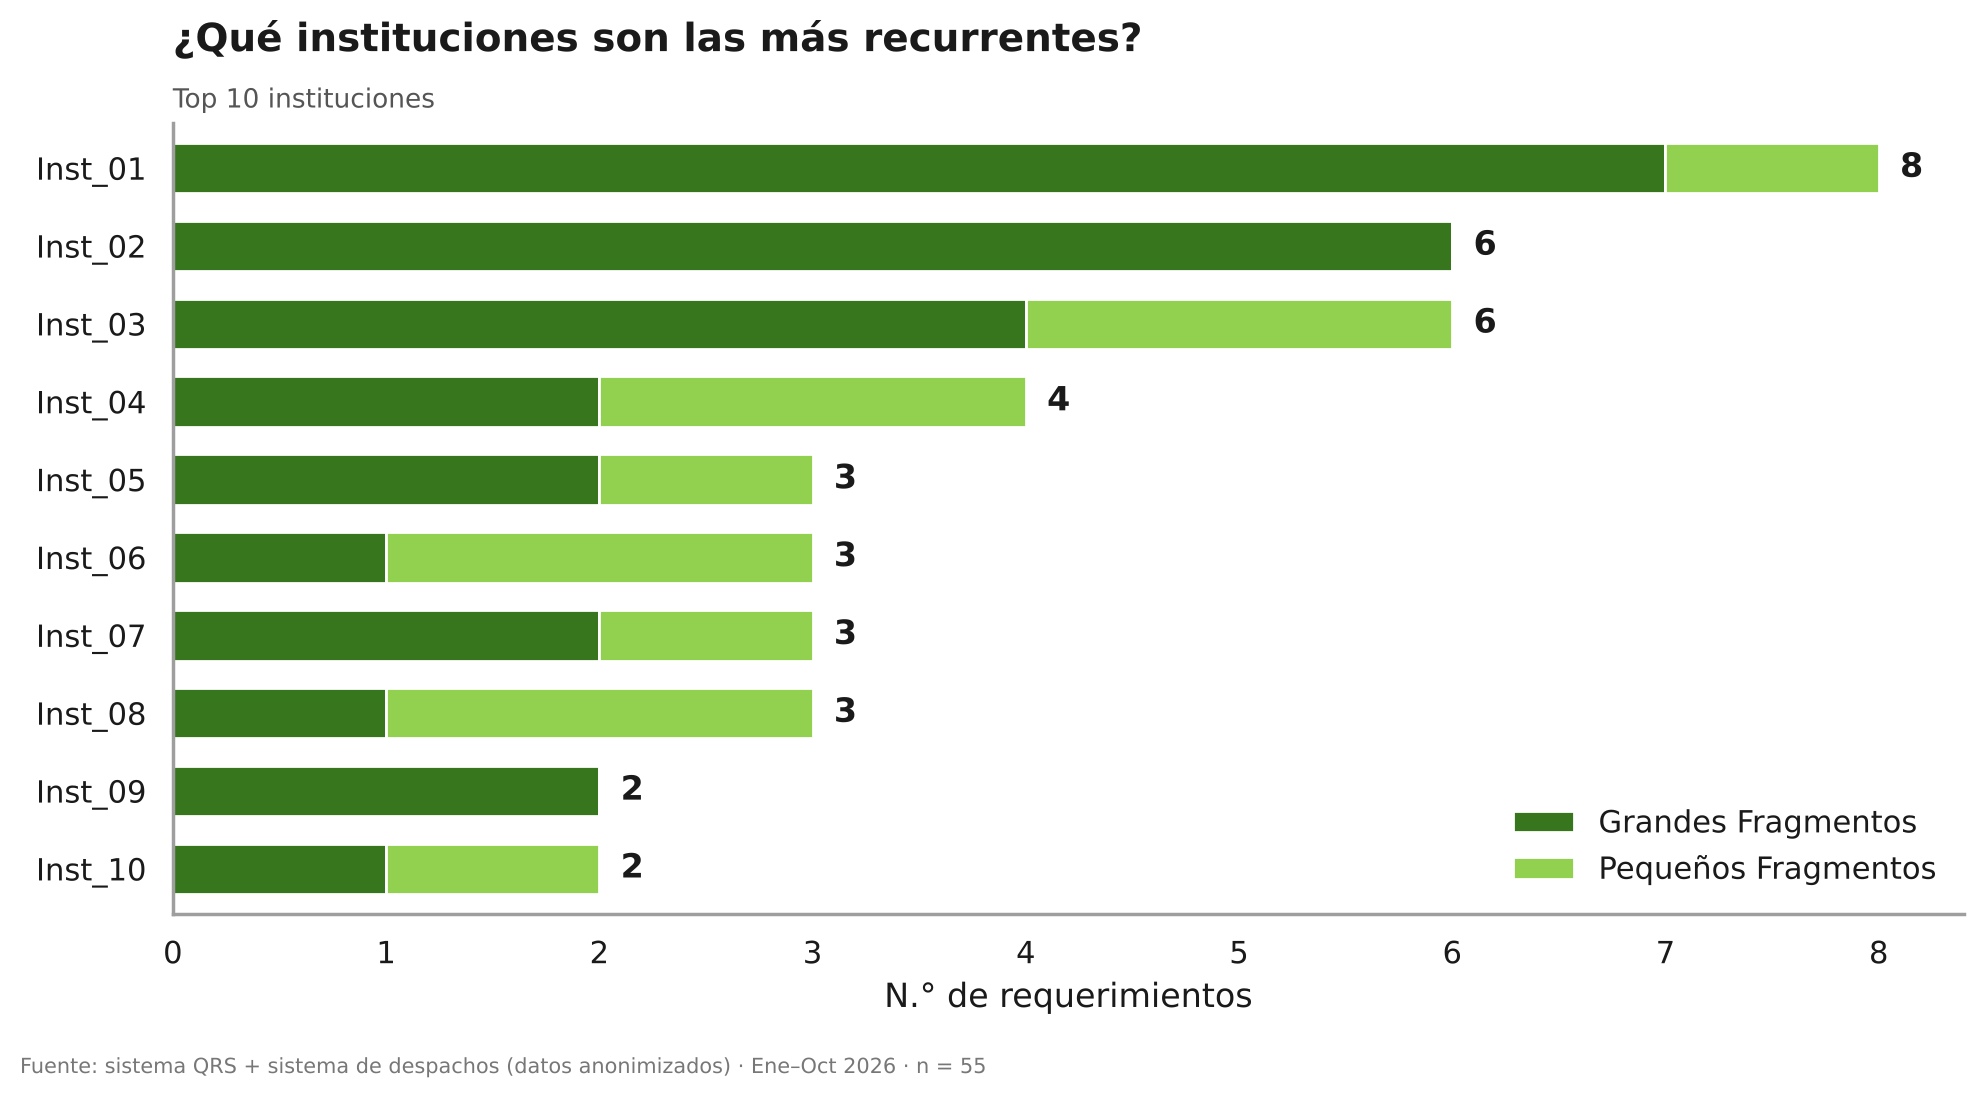

In [8]:
it = pd.crosstab(df["INSTITUCION"], df[T]).reindex(columns=[GF, PF], fill_value=0)
it = it.loc[it.sum(axis=1).sort_values(ascending=False).index[:10]].iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5.5))
it.plot.barh(stacked=True, color=[VERDE_OSCURO, VERDE_CLARO], ax=ax, width=0.65)
for i, v in enumerate(it.sum(axis=1)):
    ax.text(v + 0.1, i, str(v), va="center", fontweight="bold")
ax.set_ylabel(""); ax.set_xlabel("N.° de requerimientos"); ax.legend(LEYENDA, frameon=False, loc="lower right")
acabado(fig, ax, "03_top10_instituciones.png", "¿Qué instituciones son las más recurrentes?", "Top 10 instituciones")

**Respuesta:** Las 3 primeras instituciones suman **20 requerimientos (36 %)**.

## Pregunta 4. ¿Cómo evolucionó la demanda mes a mes?
**Gráfico:** Líneas con marcadores y área del total.

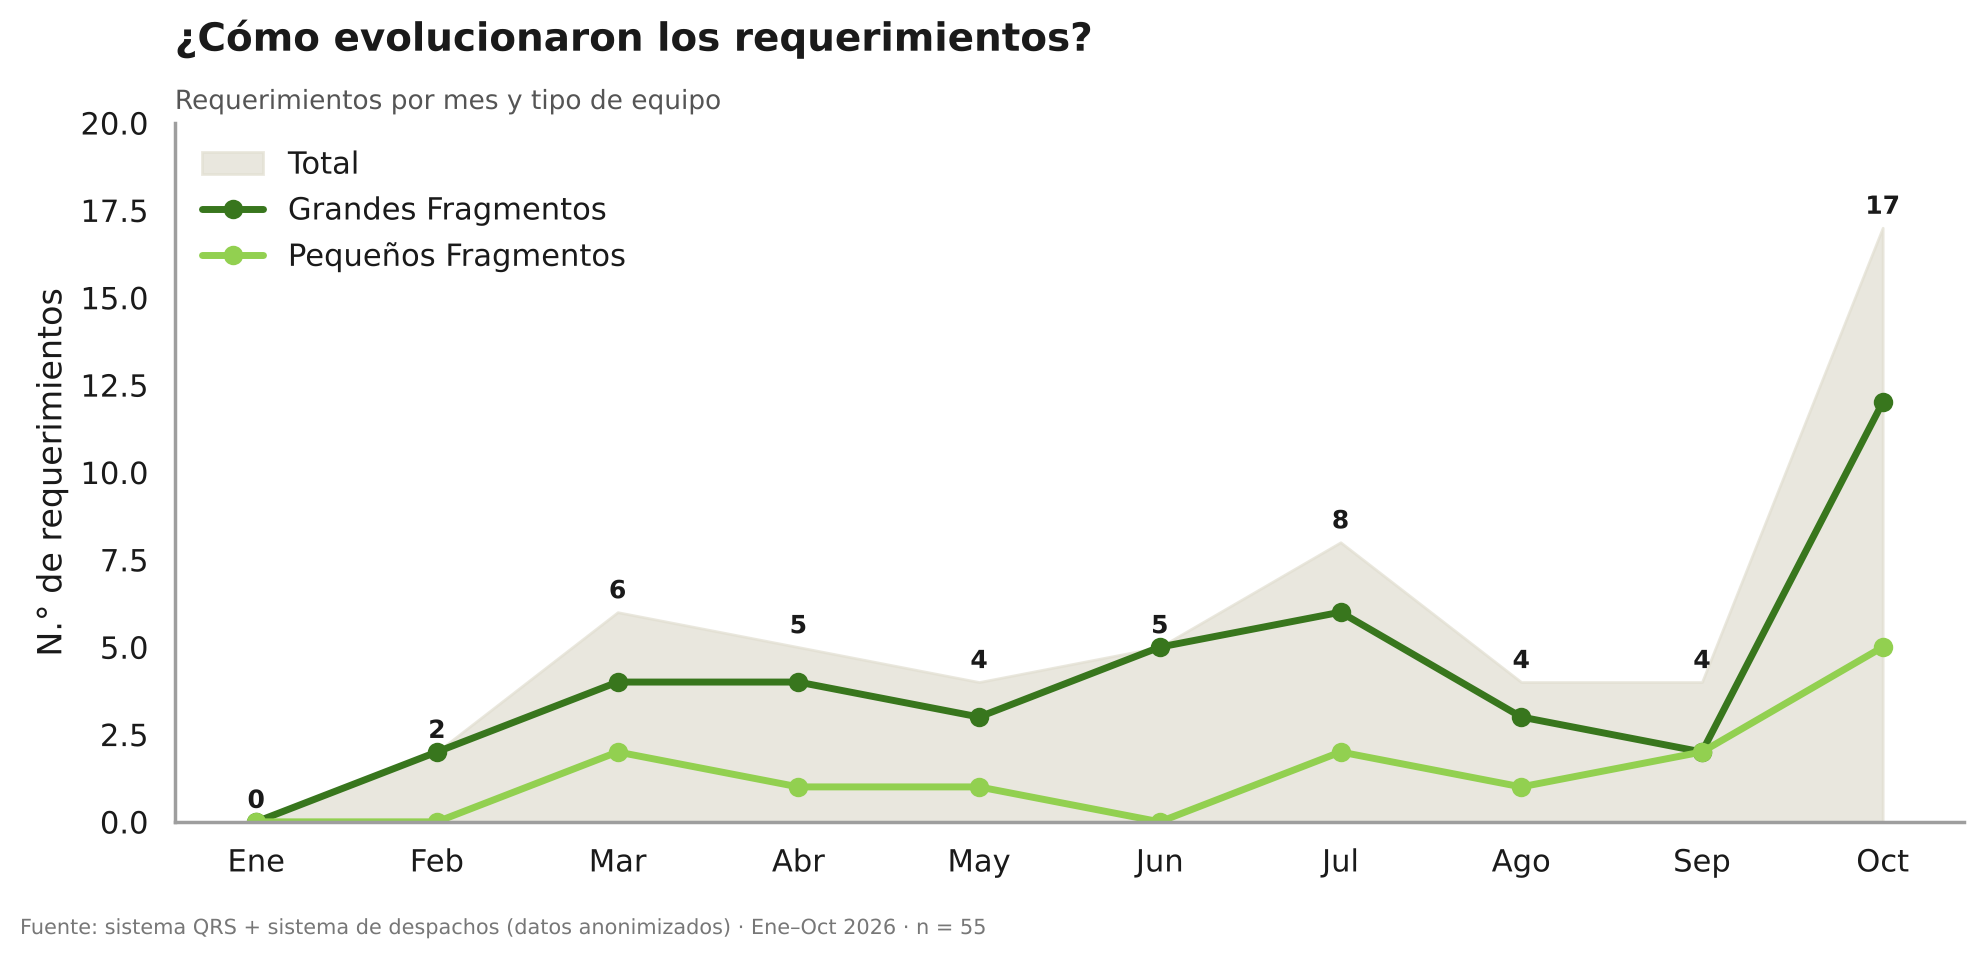

In [9]:
mt = pd.crosstab(df["MES"], df[T]).reindex(meses, fill_value=0).reindex(columns=[GF, PF], fill_value=0)
total = mt.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.fill_between(range(10), total, color=GRIS_VERDOSO, alpha=0.7, label="Total")
ax.plot(range(10), mt[GF], marker="o", color=VERDE_OSCURO, lw=2.5, label=GF)
ax.plot(range(10), mt[PF], marker="o", color=VERDE_CLARO, lw=2.5, label=PF)
for i, v in enumerate(total):
    ax.text(i, v + 0.4, str(v), ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(range(10)); ax.set_xticklabels(etiquetas)
ax.set_ylabel("N.° de requerimientos"); ax.set_ylim(0, total.max() + 3); ax.legend(frameon=False, loc="upper left")
acabado(fig, ax, "04_tendencia_mensual.png", "¿Cómo evolucionaron los requerimientos?", "Requerimientos por mes y tipo de equipo")

**Respuesta:** Entre febrero y septiembre hubo entre 2 y 8 requerimientos por mes; **octubre registró 17**, cerca del triple del promedio mensual.

## Pregunta 5. ¿En qué sistemas quirúrgicos se pide el motor eléctrico?
**Gráfico:** Top 10 sistemas en barras apiladas.

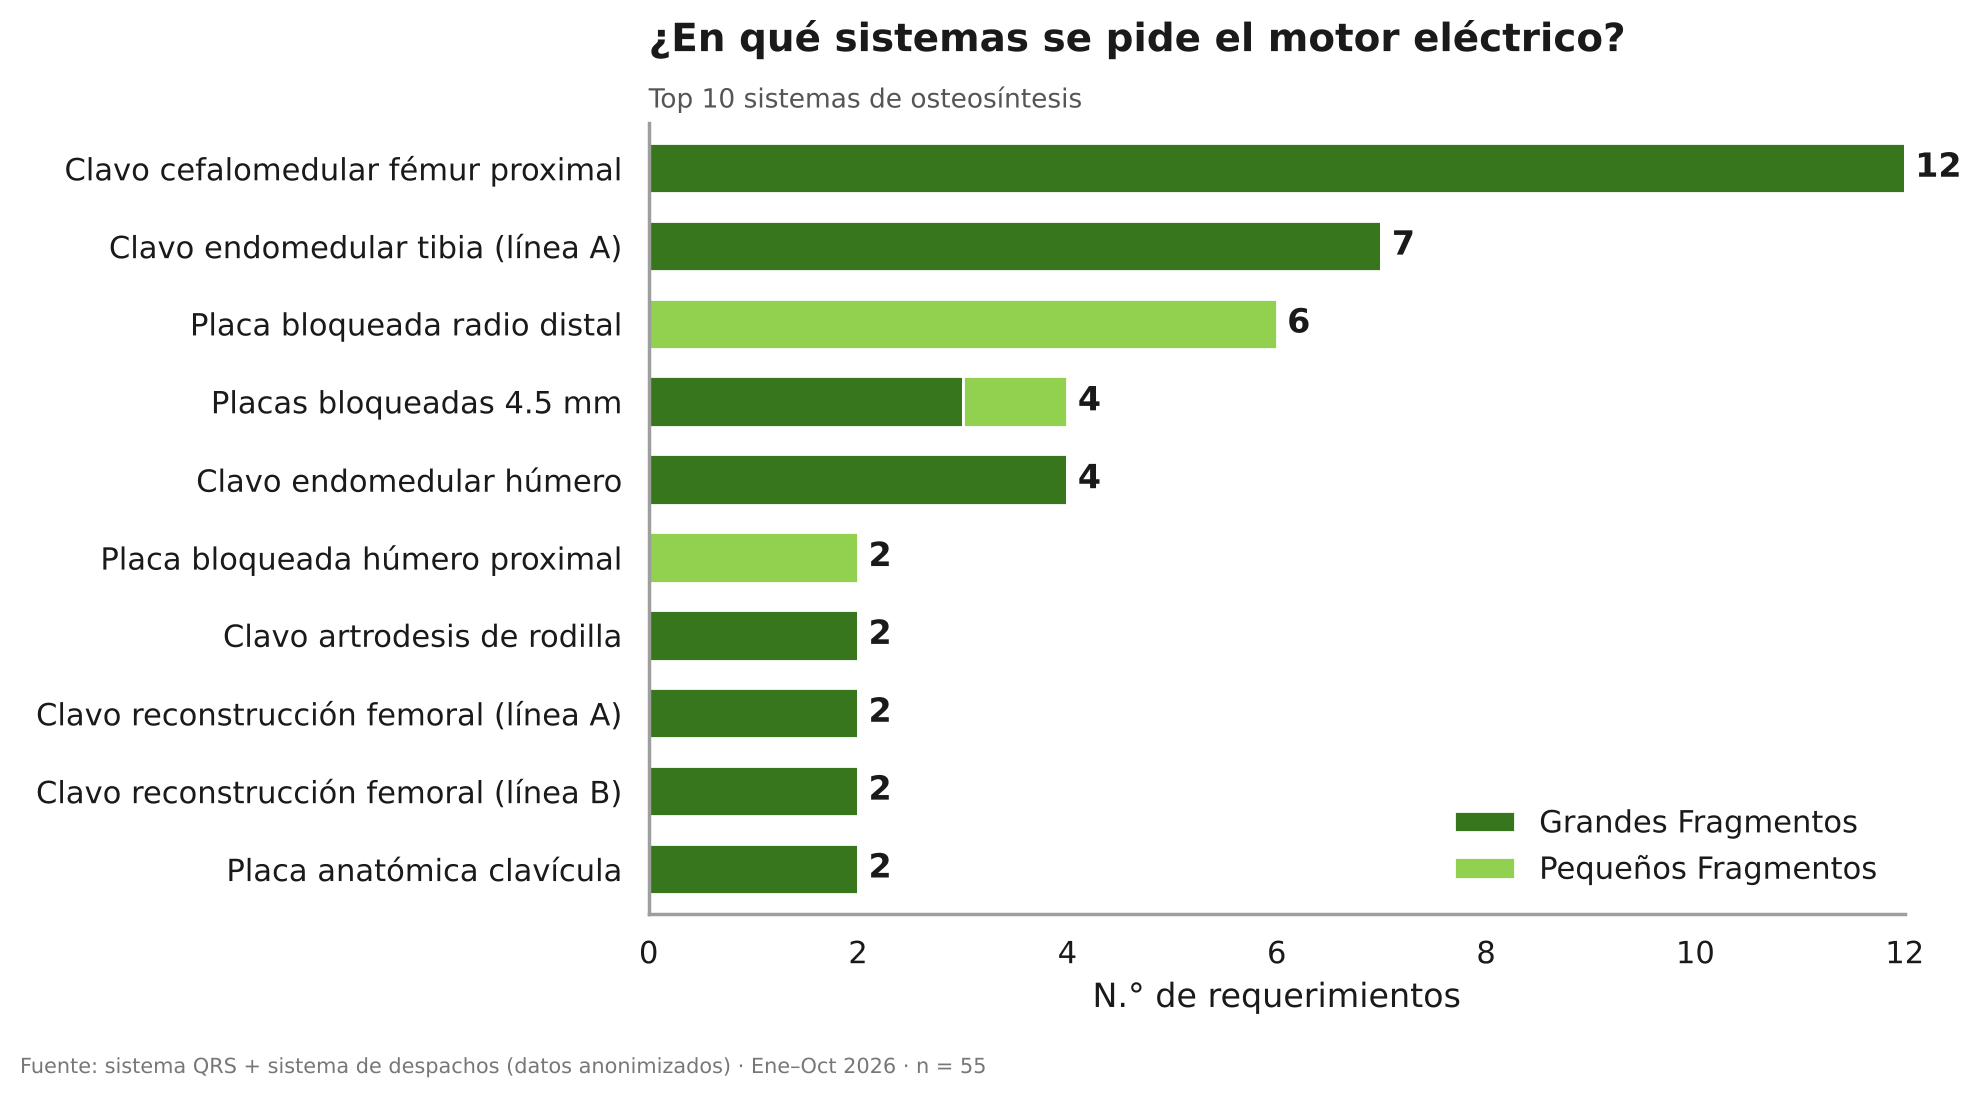

In [10]:
st = pd.crosstab(df["SISTEMA"], df[T]).reindex(columns=[GF, PF], fill_value=0)
st = st.loc[st.sum(axis=1).sort_values(ascending=False).index[:10]].iloc[::-1]
st.index = [corto(i, 40) for i in st.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
st.plot.barh(stacked=True, color=[VERDE_OSCURO, VERDE_CLARO], ax=ax, width=0.65)
for i, v in enumerate(st.sum(axis=1)):
    ax.text(v + 0.1, i, str(v), va="center", fontweight="bold")
ax.set_ylabel(""); ax.set_xlabel("N.° de requerimientos"); ax.legend(LEYENDA, frameon=False, loc="lower right")
acabado(fig, ax, "05_top10_sistemas.png", "¿En qué sistemas se pide el motor eléctrico?", "Top 10 sistemas de osteosíntesis")

**Respuesta:** Los **clavos endomedulares** (fémur proximal y tibia) lideran con Grandes Fragmentos; la **placa de radio distal** concentra Pequeños Fragmentos.

## Pregunta 6. ¿Qué pagadores están detrás de esas cirugías?
**Gráfico:** Barras horizontales ordenadas (Top 8).

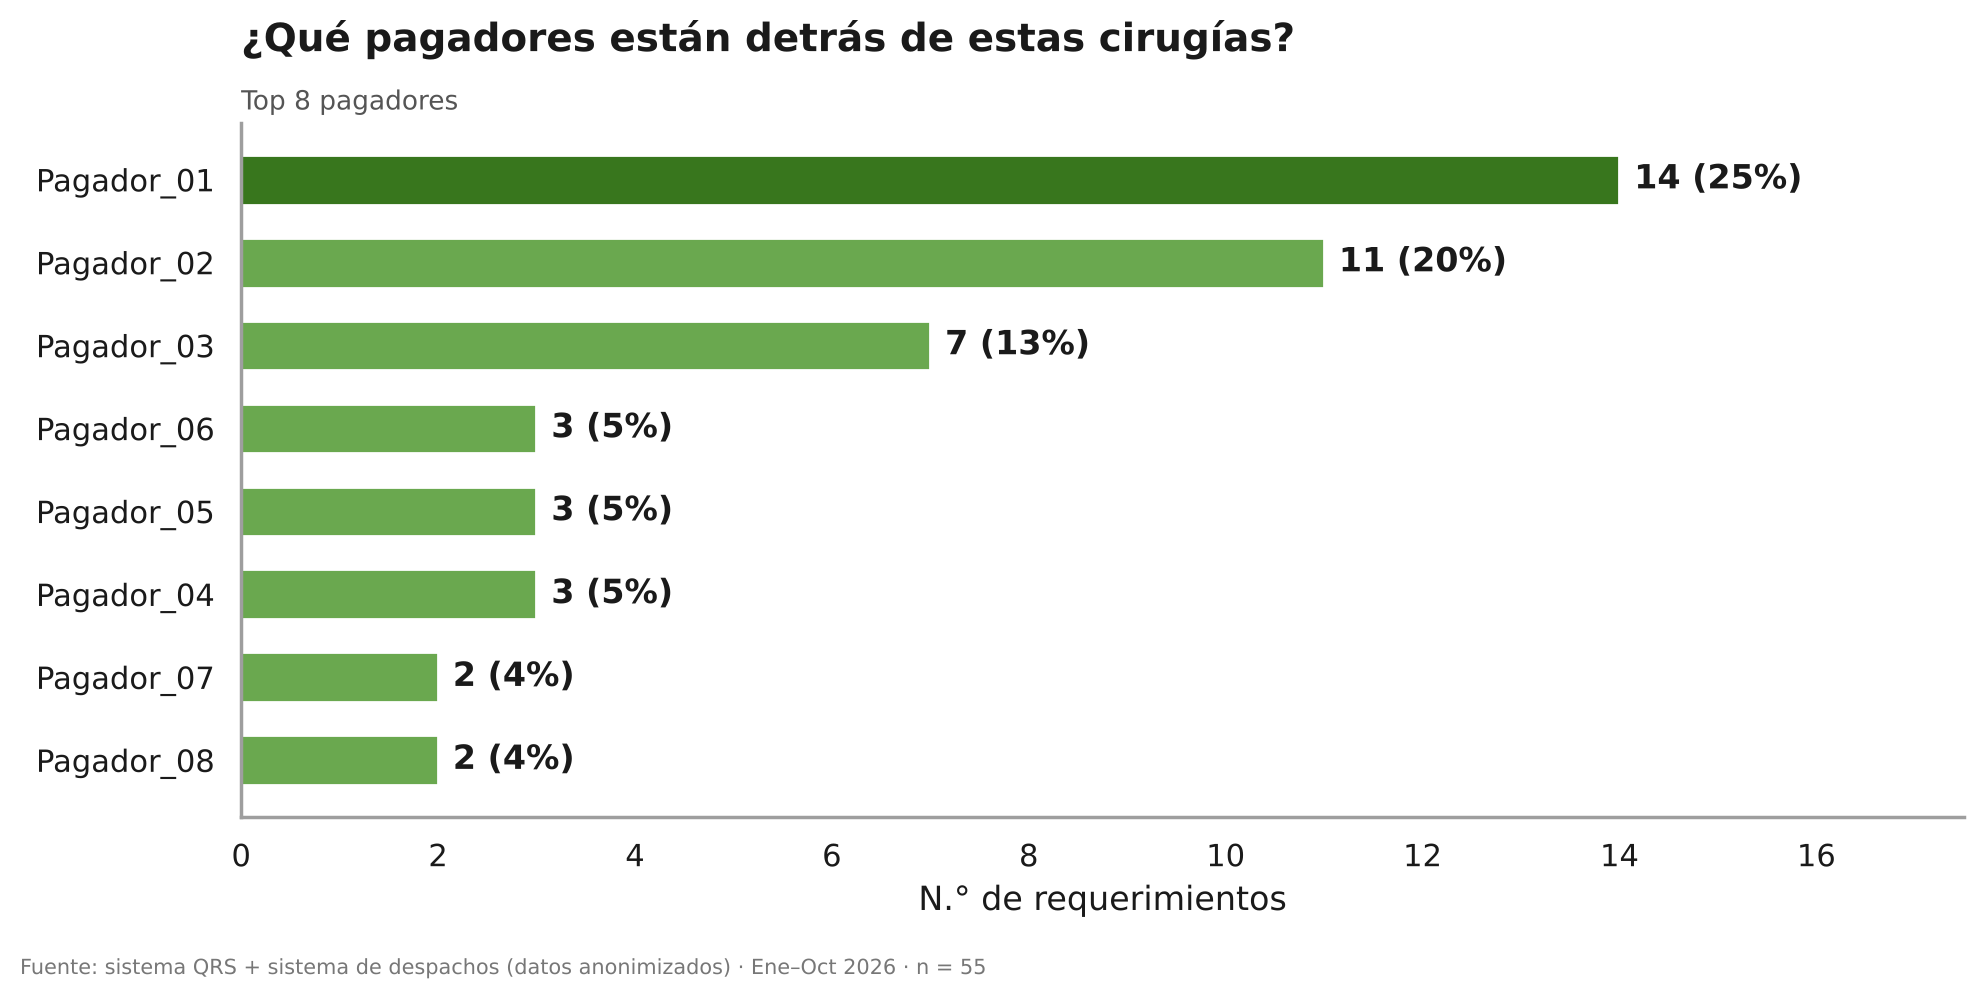

In [11]:
en = df["PAGADOR"].value_counts().head(8).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(en.index, en.values, color=[VERDE_OSCURO if v == en.max() else VERDE_MEDIO for v in en.values], height=0.6)
for i, v in enumerate(en.values):
    ax.text(v + 0.15, i, f"{v} ({v/N:.0%})", va="center", fontweight="bold")
ax.set_xlabel("N.° de requerimientos"); ax.set_xlim(0, en.max() * 1.25)
acabado(fig, ax, "06_pagadores.png", "¿Qué pagadores están detrás de estas cirugías?", "Top 8 pagadores")

**Respuesta:** Dos pagadores concentran el **45 %** de las cirugías asociadas.

## Pregunta 7. ¿Dónde y cuándo se concentran?
**Gráfico:** Mapa de calor Ciudad × Mes.

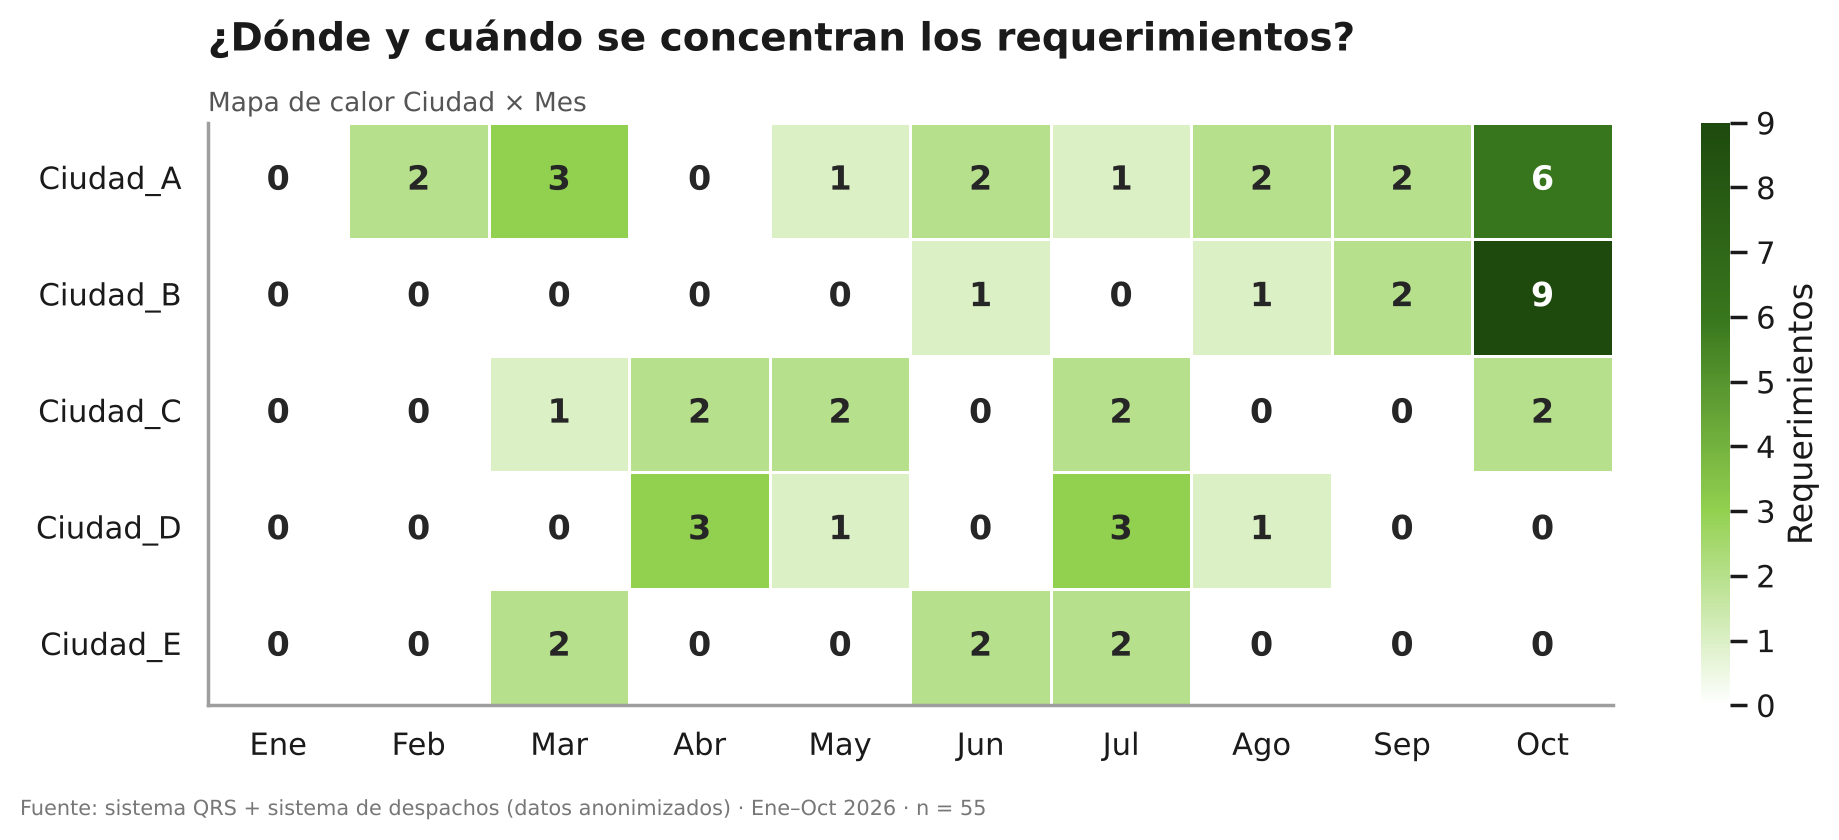

In [12]:
hm = pd.crosstab(df["CIUDAD"], df["MES"]).reindex(columns=meses, fill_value=0)
hm.columns = etiquetas
hm = hm.loc[hm.sum(axis=1).sort_values(ascending=False).index]
cmap_verde = LinearSegmentedColormap.from_list("verdes", ["#FFFFFF", VERDE_CLARO, VERDE_OSCURO, "#1E4A0E"])

fig, ax = plt.subplots(figsize=(10, 4.2))
sns.heatmap(hm, annot=True, fmt="d", cmap=cmap_verde, linewidths=1, linecolor="white",
            cbar_kws={"label": "Requerimientos"}, annot_kws={"fontweight": "bold"}, ax=ax)
ax.set_xlabel(""); ax.set_ylabel(""); plt.setp(ax.get_yticklabels(), rotation=0)
acabado(fig, ax, "07_mapa_calor_ciudad_mes.png", "¿Dónde y cuándo se concentran los requerimientos?", "Mapa de calor Ciudad × Mes")

**Respuesta:** **Ciudad_B** pasó de 2 requerimientos en septiembre a 9 en octubre; **Ciudad_A** registra reportes en 8 de los 10 meses.

## Pregunta 8. ¿Cuántos reportes implican riesgo de perder la cirugía?
**Gráfico:** Barras 100 % apiladas.

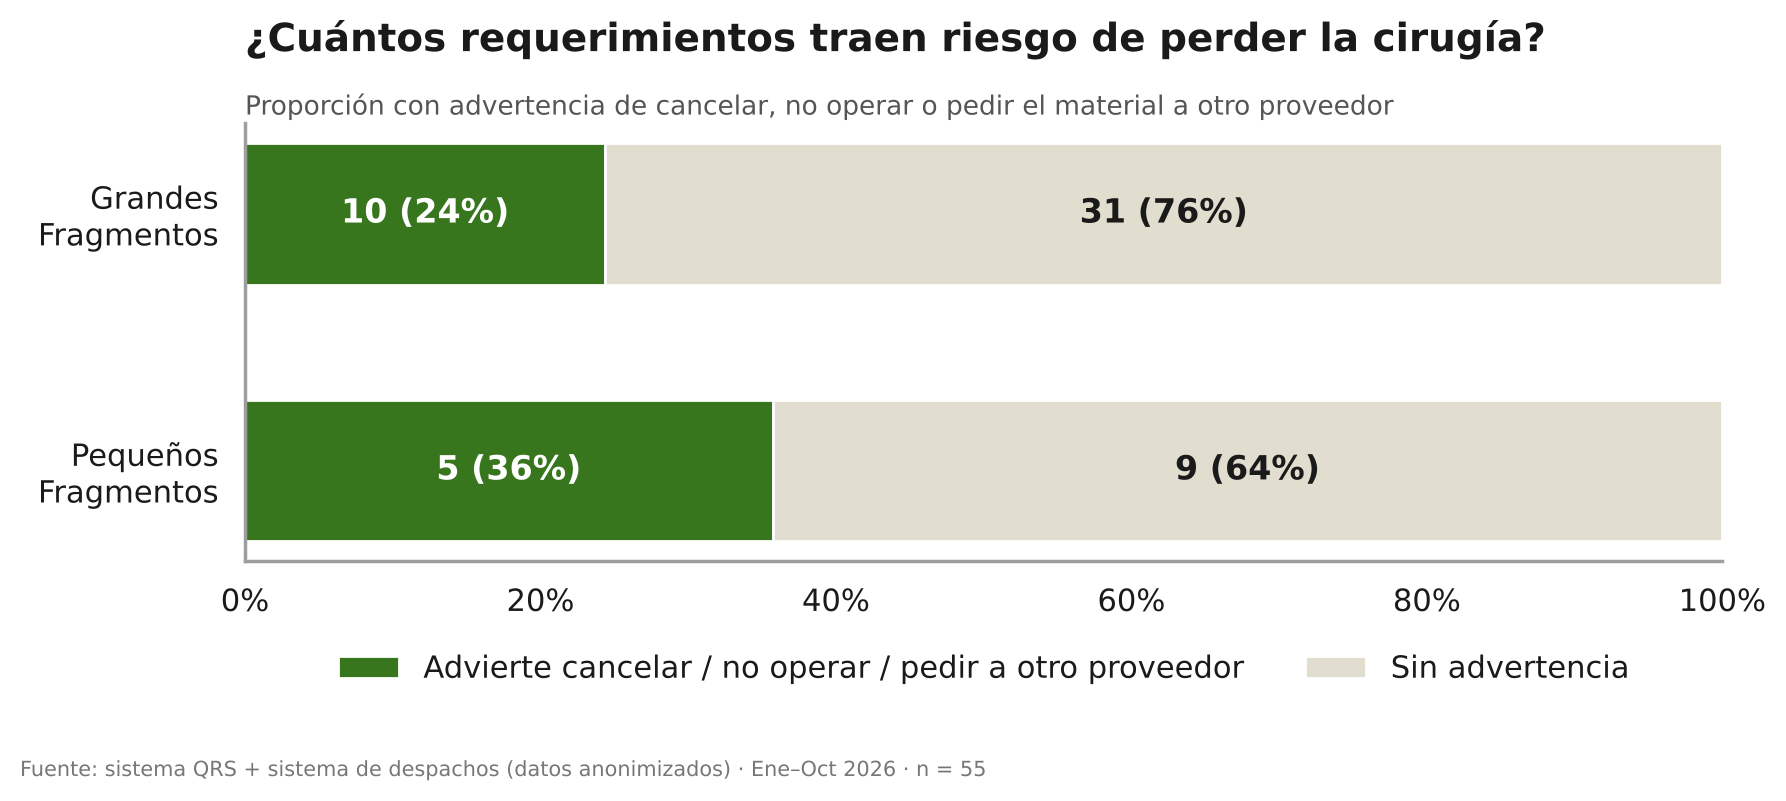

In [13]:
es  = pd.crosstab(df[T], df["ADVERTENCIA"]).reindex(index=[GF, PF], columns=["Sí", "No"], fill_value=0)
pct = es.div(es.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 4))
izq = np.zeros(2)
for col, color, etiqueta in [("Sí", VERDE_OSCURO, "Advierte cancelar / no operar / pedir a otro proveedor"),
                             ("No", GRIS_VERDOSO, "Sin advertencia")]:
    ax.barh(["Grandes\nFragmentos", "Pequeños\nFragmentos"], pct[col].values, left=izq, color=color, height=0.55, label=etiqueta)
    for i, (p, n) in enumerate(zip(pct[col].values, es[col].values)):
        ax.text(izq[i] + p/2, i, f"{n} ({p:.0%})", ha="center", va="center",
                color="white" if col == "Sí" else NEGRO, fontweight="bold")
    izq += pct[col].values
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
acabado(fig, ax, "08_advertencias_por_tipo.png", "¿Cuántos requerimientos traen riesgo de perder la cirugía?",
        "Proporción con advertencia de cancelar, no operar o pedir el material a otro proveedor")

**Respuesta:** El **27 %** de los requerimientos (15) incluye una advertencia de escalamiento; la proporción es mayor en Pequeños Fragmentos (36 %) que en Grandes (24 %), aunque con pocos casos.

## Pregunta 9. ¿Pocas instituciones explican la mayoría?
**Gráfico:** Diagrama de Pareto.

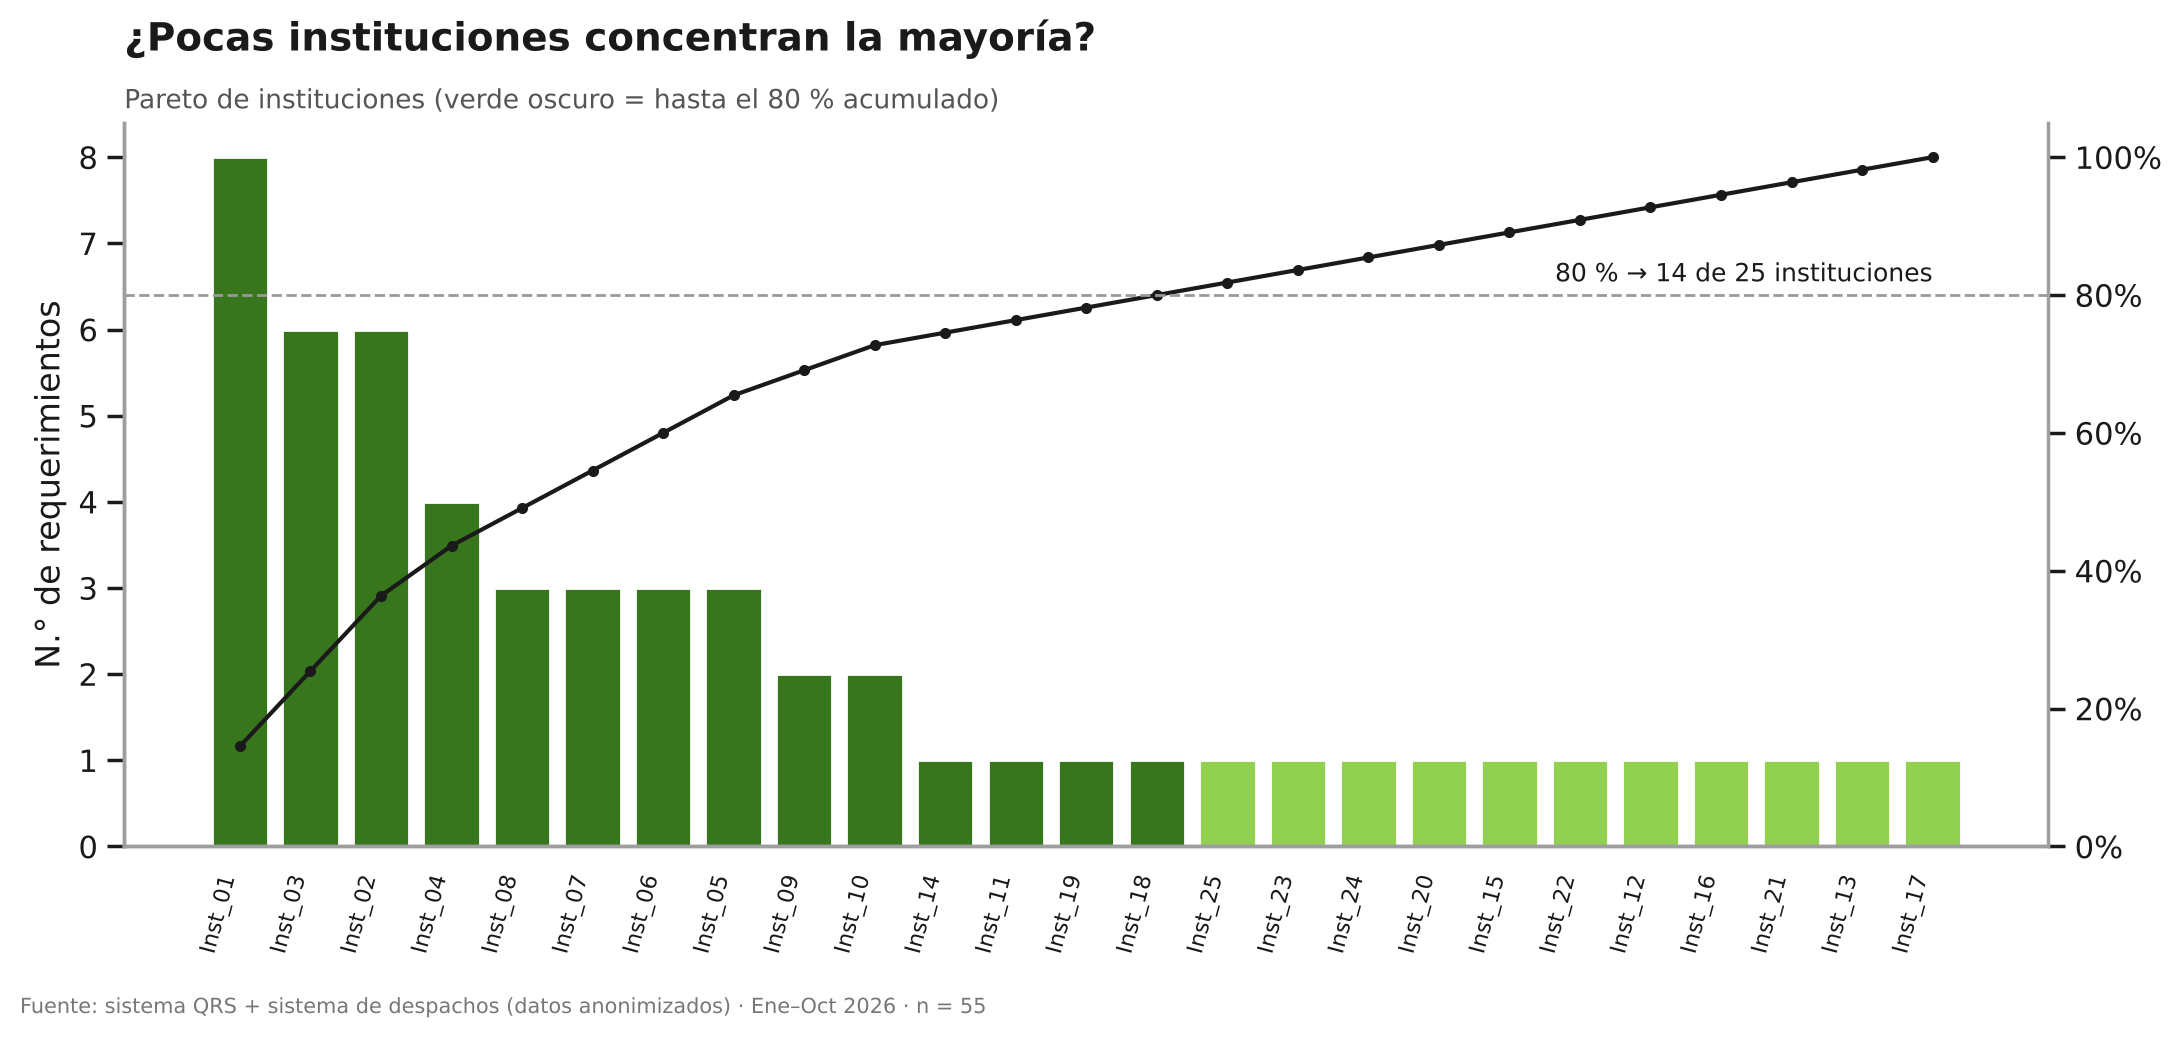

In [14]:
pi  = df["INSTITUCION"].value_counts()
acu = pi.cumsum() / pi.sum()
k   = (acu <= 0.8).sum()

fig, ax = plt.subplots(figsize=(11, 5.2))
x = range(len(pi))
ax.bar(x, pi.values, color=[VERDE_OSCURO if c <= 0.8 else VERDE_CLARO for c in acu.values])
ax2 = ax.twinx()
ax2.plot(x, acu.values, color=NEGRO, marker="o", ms=3, lw=1.5)
ax2.axhline(0.8, ls="--", color="#999999", lw=1)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(1)); ax2.set_ylim(0, 1.05)
sns.despine(ax=ax2, right=False)
ax.set_xticks(list(x)); ax.set_xticklabels(pi.index, rotation=75, ha="right", fontsize=8)
ax.set_ylabel("N.° de requerimientos")
ax2.text(len(pi) - 1, 0.82, f"80 % → {k} de {len(pi)} instituciones", ha="right", fontsize=9)
acabado(fig, ax, "09_pareto_instituciones.png", "¿Pocas instituciones concentran la mayoría?",
        "Pareto de instituciones (verde oscuro = hasta el 80 % acumulado)")

**Respuesta:** **14 de 25 instituciones** explican el 80 % de los requerimientos; 15 instituciones tienen un solo reporte.

## Conclusiones
1. La demanda de motor eléctrico es principalmente de **Grandes Fragmentos (75 %)**, asociada a clavos endomedulares de fémur y tibia.
2. La necesidad está **geográficamente concentrada**: dos ciudades de una misma región suman el 58 %.
3. La demanda **aumentó en el último mes** del periodo.
4. Más de **1 de cada 4 reportes** advierte la posible pérdida de la cirugía, lo que convierte la necesidad en un riesgo comercial.

**Limitación:** el análisis cuenta reportes, no cirugías ni inventario; para calcular tasas haría falta el número de procedimientos por institución y el inventario de equipos.